In [5]:
!pip install skorch -q

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

# pour avoir les mêmes résultats à chaque exécution
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("On travaille sur :", device)

# dossier pour sauvegarder les graphes (utiles pour le README)
os.makedirs("/kaggle/working/images", exist_ok=True)
IMG = "/kaggle/working/images/"

DATA = "/kaggle/input/datasets/dgawlik/nyse"
print(os.listdir(DATA))

On travaille sur : cuda
['prices-split-adjusted.csv', 'fundamentals.csv', 'prices.csv', 'securities.csv']


In [6]:
df = pd.read_csv(f"{DATA}/prices-split-adjusted.csv", parse_dates=["date"])
display(df.head())

print("Dimensions :", df.shape)
df.info()
print(df.describe())
print("\nValeurs manquantes :\n", df.isnull().sum())
print("Doublons :", df.duplicated().sum())
print("Nombre d'actions :", df["symbol"].nunique())
print("Période :", df["date"].min(), "→", df["date"].max())

,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


Dimensions : (851264, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB
                                date           open          close  \
count                         851264  851264.000000  851264.000000   
mean   2013-07-21 02:56:29.294037760      64.993618      65.011913   
min              2010-01-04 00:00:00       1.660000       1.590000   
25%              2011-10-19 00:00:00      31.270000      31.292776   
50%              2013-08-02 00:00:00  

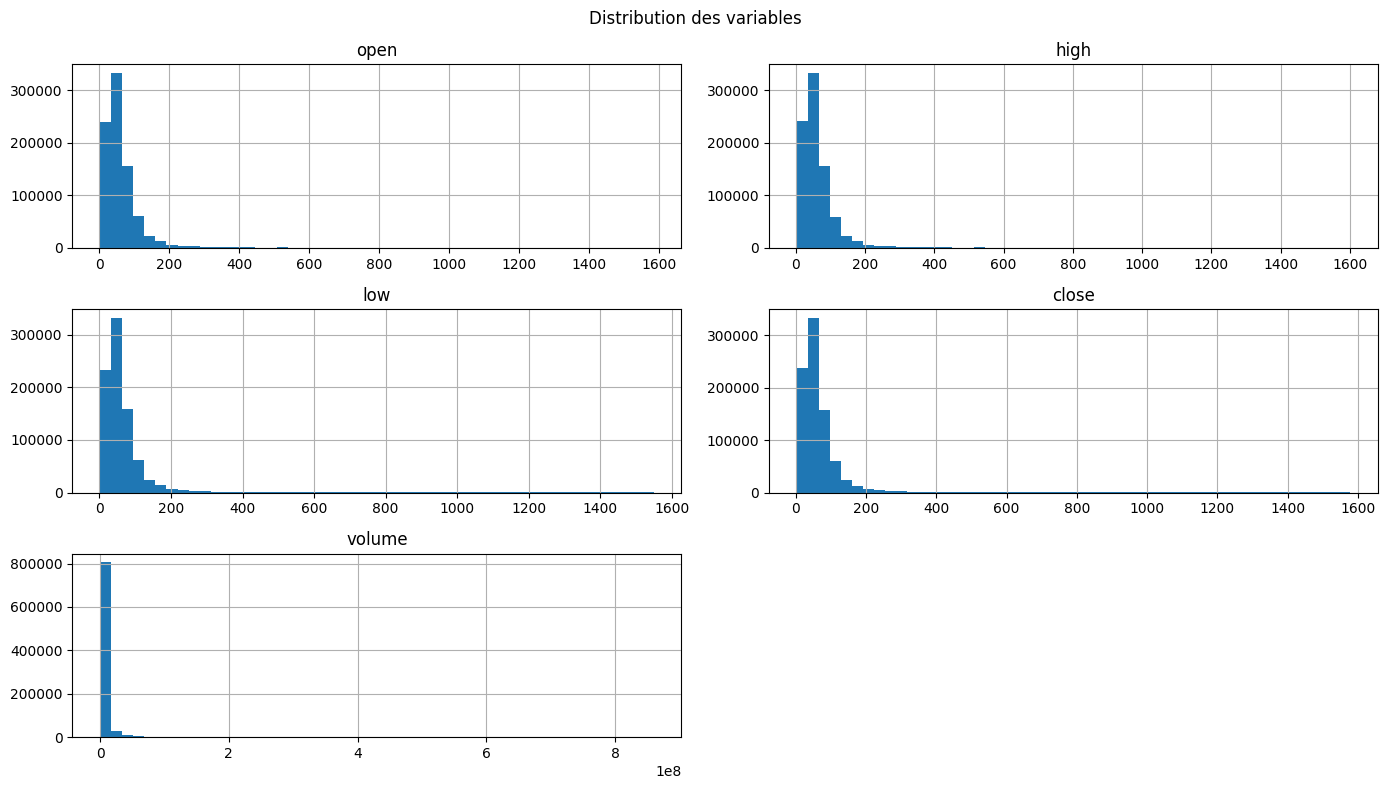

In [7]:
cols = ["open", "high", "low", "close", "volume"]

df[cols].hist(bins=50, figsize=(14, 8))
plt.suptitle("Distribution des variables")
plt.tight_layout()
plt.savefig(IMG + "eda_hist.png", dpi=150)
plt.show()

Les variables de prix (`open`, `high`, `low`, `close`) ont des distributions quasi identiques et très asymétriques à droite : la plupart des valeurs se situent entre 0 et 100 $, avec une longue queue jusqu'à environ 1 600 $. Le `volume` est encore plus écrasé près de zéro (maximum d'environ 8,5 × 10⁸), et ses échelles très différentes de celles des prix rendent la normalisation indispensable.

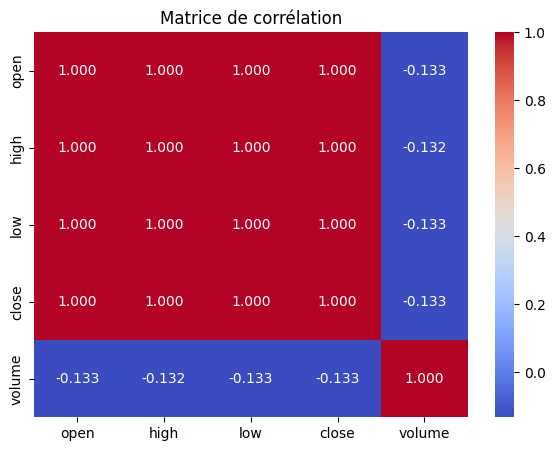

In [8]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Matrice de corrélation")
plt.savefig(IMG + "eda_corr.png", dpi=150, bbox_inches="tight")
plt.show()

open, high, low et close sont corrélés à presque 1 (environ 0.999), ce qui est logique : le prix de clôture d’une journée reste proche de son prix d’ouverture. Le volume est faiblement corrélé aux prix (valeur). Cela laisse penser que la tâche sera assez facile et que le modèle atteindra un R au carre très élevé.

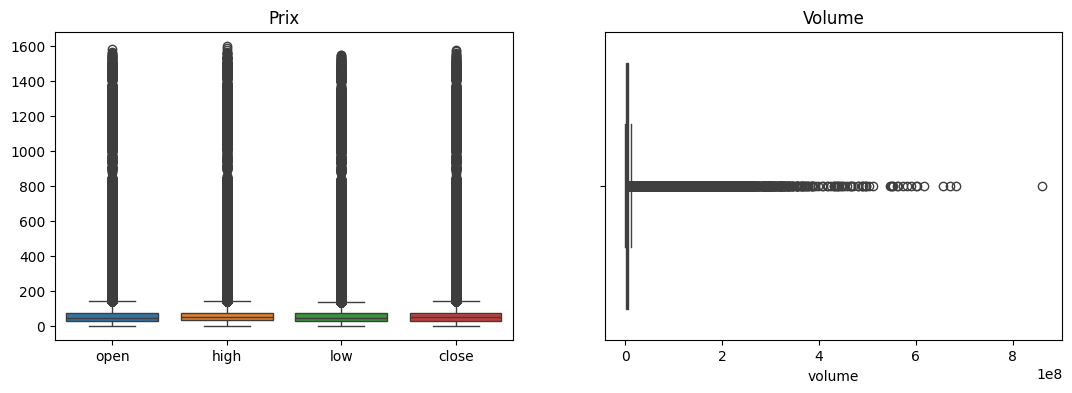

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df[["open", "high", "low", "close"]], ax=ax[0])
ax[0].set_title("Prix")
sns.boxplot(x=df["volume"], ax=ax[1])
ax[1].set_title("Volume")
plt.savefig(IMG + "eda_box.png", dpi=150, bbox_inches="tight")
plt.show()

Les boxplots montrent beaucoup de valeurs extrêmes, surtout pour le volume. Ce ne sont pas forcément des erreurs : ce sont des actions très chères ou des jours d’activité exceptionnelle. Je les ai gardées, car elles représentent des situations réelles du marché.

In [17]:
features = ["open", "low", "high", "volume"]
X = df[features].values
y = df["close"].values.reshape(-1, 1)

# 80% pour entraîner, 20% pour tester
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# normalisation : on apprend la moyenne/écart-type sur le train SEULEMENT
sx, sy = StandardScaler(), StandardScaler()
X_train = sx.fit_transform(X_train).astype("float32")
X_test  = sx.transform(X_test).astype("float32")
y_train = sy.fit_transform(y_train).astype("float32")
y_test  = sy.transform(y_test).astype("float32")

# conversion en tenseurs PyTorch
X_train_t = torch.tensor(X_train).to(device)
y_train_t = torch.tensor(y_train).to(device)
X_test_t  = torch.tensor(X_test).to(device)
y_test_t  = torch.tensor(y_test).to(device)

print("Train :", X_train_t.shape, "| Test :", X_test_t.shape)

Train : torch.Size([681011, 4]) | Test : torch.Size([170253, 4])


J’ai séparé les données en 80 % pour l’entraînement et 20 % pour le test. Le StandardScaler est ajusté uniquement sur le train, puis appliqué au test, pour éviter la fuite de données (le modèle ne doit rien savoir du test). La cible est aussi normalisée pour que la perte MSE reste dans une échelle raisonnable.

In [11]:
class MLP(nn.Module):
    """MLP pour la régression : Linear -> ReLU (-> BatchNorm / Dropout) ... -> Linear(1)"""
    def __init__(self, input_dim=4, hidden=(64, 32), dropout=0.0, batchnorm=False):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))   # une seule sortie, sans activation
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

print(MLP(4, hidden=(64, 32)))

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [23]:
def r2(y_true, y_pred):
    return 1 - ((y_true - y_pred) ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum()

def train_model(model, lr=1e-3, epochs=30, batch_size=1024,
                optimizer_cls=torch.optim.Adam, weight_decay=0.0,
                early_stopping=False, patience=5):
    model.to(device)
    opt = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()
    n = X_train_t.shape[0]

    hist = {"train_loss": [], "test_loss": [], "train_r2": [], "test_r2": []}
    best, wait = float("inf"), 0

    for ep in range(epochs):
        # --- phase d'entraînement ---
        model.train()
        perm = torch.randperm(n, device=device)      # mélange des indices
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_train_t[idx], y_train_t[idx]  # batch pris directement
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()

        # --- évaluation ---
        model.eval()
        with torch.no_grad():
            p_tr, p_te = model(X_train_t), model(X_test_t)
            tl = loss_fn(p_tr, y_train_t).item()
            vl = loss_fn(p_te, y_test_t).item()
            hist["train_loss"].append(tl)
            hist["test_loss"].append(vl)
            hist["train_r2"].append(r2(y_train_t, p_tr).item())
            hist["test_r2"].append(r2(y_test_t, p_te).item())

        print(f"Epoch {ep+1}/{epochs} | train_loss={tl:.5f} | test_loss={vl:.5f}")

        # --- early stopping ---
        if early_stopping:
            if vl < best:
                best, wait = vl, 0
            else:
                wait += 1
                if wait >= patience:
                    print(f"Arrêt anticipé à l'epoch {ep + 1}")
                    break
    return hist

Architecture choisie : un MLP avec 4 entrées (les 4 variables), des couches cachées Linear + ReLU, et 1 neurone de sortie sans activation, car on prédit une valeur continue. J’ai choisi ReLU car elle évite le problème du gradient qui disparaît (vu avec la sigmoïde et tanh dans le cours) et converge vite. La fonction de perte est la MSE, qui correspond au maximum de vraisemblance sous l’hypothèse d’un bruit gaussien.

La boucle d’entraînement suit les 4 étapes classiques : zero_grad et forward et backward et step. Comme l’accuracy n’existe pas en régression, j’utilise le R au carre comme mesure de performance : plus il est proche de 1, meilleur est le modèle.

In [19]:
from skorch import NeuralNetRegressor

# le GridSearch est lent : on utilise un sous-échantillon de 50 000 lignes
idx = np.random.choice(len(X_train), 50000, replace=False)
Xs, ys = X_train[idx], y_train[idx]

# skorch sert à rendre un modèle PyTorch compatible avec sklearn
net = NeuralNetRegressor(
    module=MLP,
    module__input_dim=4,
    criterion=nn.MSELoss,
    batch_size=256,
    max_epochs=20,
    verbose=0,
    device=device,
)

param_grid = {
    "lr": [1e-2, 1e-3],
    "optimizer": [torch.optim.Adam, torch.optim.SGD, torch.optim.RMSprop],
    "max_epochs": [20, 40],
    "module__hidden": [(32,), (64, 32), (128, 64, 32)],
}
# 2 x 3 x 2 x 3 = 36 combinaisons, x 3 folds = 108 entraînements

In [20]:
gs = GridSearchCV(net, param_grid, cv=3, scoring="r2", n_jobs=1, refit=False, verbose=1)
gs.fit(Xs, ys)

print("Meilleurs paramètres :", gs.best_params_)
print("Meilleur R² (validation croisée) :", round(gs.best_score_, 5))

res = pd.DataFrame(gs.cv_results_)
pc = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score"]
display(res[pc].sort_values("mean_test_score", ascending=False).head(10))

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Meilleurs paramètres : {'lr': 0.001, 'max_epochs': 40, 'module__hidden': (32,), 'optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur R² (validation croisée) : 0.99987


,param_lr,param_max_epochs,param_module__hidden,param_optimizer,mean_test_score
27,0.001,40,"(32,)",<class 'torch.optim.adam.Adam'>,0.999874
30,0.001,40,"(64, 32)",<class 'torch.optim.adam.Adam'>,0.999854
18,0.001,20,"(32,)",<class 'torch.optim.adam.Adam'>,0.999835
21,0.001,20,"(64, 32)",<class 'torch.optim.adam.Adam'>,0.999825
33,0.001,40,"(128, 64, 32)",<class 'torch.optim.adam.Adam'>,0.999810
16,0.010,40,"(128, 64, 32)",<class 'torch.optim.sgd.SGD'>,0.999784
24,0.001,20,"(128, 64, 32)",<class 'torch.optim.adam.Adam'>,0.999783
9,0.010,40,"(32,)",<class 'torch.optim.adam.Adam'>,0.999710
13,0.010,40,"(64, 32)",<class 'torch.optim.sgd.SGD'>,0.999669
4,0.010,20,"(64, 32)",<class 'torch.optim.sgd.SGD'>,0.999621


J’ai testé 36 combinaisons de learning rate (0.01 / 0.001), optimiseur (Adam / SGD / RMSprop), nombre d’epochs (20 / 40) et architecture (1, 2 ou 3 couches cachées), avec une validation croisée à 3 plis. Pour gagner du temps, la recherche s’est faite sur un sous-échantillon de 50 000 lignes.

In [25]:
bp = gs.best_params_

torch.manual_seed(42)
model1 = MLP(4, hidden=bp["module__hidden"])
h1 = train_model(model1, lr=bp["lr"], epochs=bp["max_epochs"],
                 batch_size=1024, optimizer_cls=bp["optimizer"])

print("Train R² final :", round(h1["train_r2"][-1], 5))
print("Test  R² final :", round(h1["test_r2"][-1], 5))

Epoch 1/40 | train_loss=0.00053 | test_loss=0.00054
Epoch 2/40 | train_loss=0.00038 | test_loss=0.00040
Epoch 3/40 | train_loss=0.00030 | test_loss=0.00031
Epoch 4/40 | train_loss=0.00025 | test_loss=0.00026
Epoch 5/40 | train_loss=0.00022 | test_loss=0.00023
Epoch 6/40 | train_loss=0.00021 | test_loss=0.00022
Epoch 7/40 | train_loss=0.00020 | test_loss=0.00021
Epoch 8/40 | train_loss=0.00020 | test_loss=0.00021
Epoch 9/40 | train_loss=0.00018 | test_loss=0.00019
Epoch 10/40 | train_loss=0.00018 | test_loss=0.00019
Epoch 11/40 | train_loss=0.00019 | test_loss=0.00020
Epoch 12/40 | train_loss=0.00016 | test_loss=0.00017
Epoch 13/40 | train_loss=0.00021 | test_loss=0.00022
Epoch 14/40 | train_loss=0.00015 | test_loss=0.00016
Epoch 15/40 | train_loss=0.00013 | test_loss=0.00014
Epoch 16/40 | train_loss=0.00012 | test_loss=0.00012
Epoch 17/40 | train_loss=0.00010 | test_loss=0.00011
Epoch 18/40 | train_loss=0.00009 | test_loss=0.00010
Epoch 19/40 | train_loss=0.00008 | test_loss=0.00009
Ep

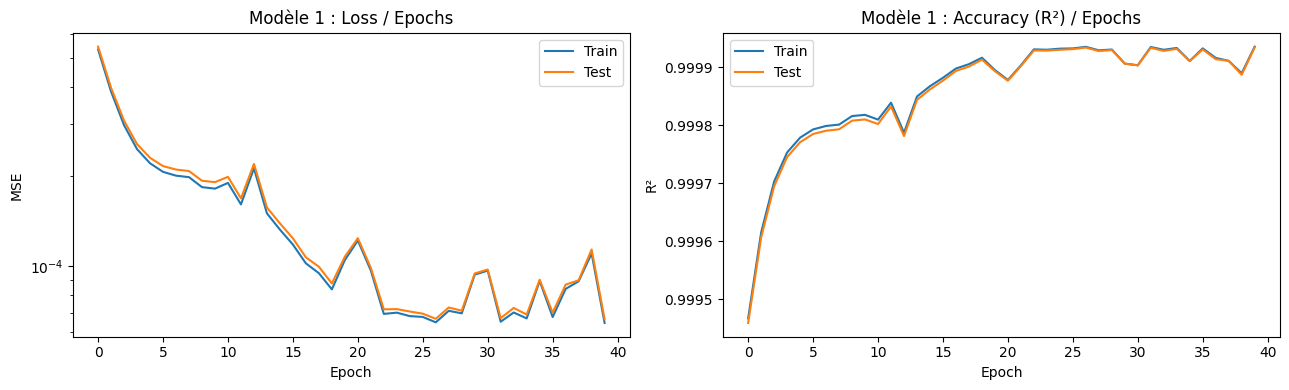

In [26]:
def plot_history(h, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))

    ax[0].plot(h["train_loss"], label="Train")
    ax[0].plot(h["test_loss"], label="Test")
    ax[0].set_title(f"{title} : Loss / Epochs")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("MSE")
    ax[0].set_yscale("log"); ax[0].legend()

    ax[1].plot(h["train_r2"], label="Train")
    ax[1].plot(h["test_r2"], label="Test")
    ax[1].set_title(f"{title} : Accuracy (R²) / Epochs")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("R²"); ax[1].legend()

    plt.tight_layout()
    plt.savefig(IMG + fname, dpi=150, bbox_inches="tight")
    plt.show()

plot_history(h1, "Modèle 1", "loss_model1.png")

La loss (MSE) chute rapidement durant les premières epochs puis se stabilise autour de 10⁻⁴ avec quelques oscillations, et le R² dépasse 0,9999 sur le train comme sur le test. Les courbes train et test sont quasiment confondues, donc il n'y a ni overfitting ni underfitting, et les petites oscillations en fin d'entraînement indiquent un learning rate un peu élevé pour la phase finale.


In [27]:
hid, lr, ep = bp["module__hidden"], bp["lr"], bp["max_epochs"]
Adam = torch.optim.Adam
bs = 256

def nouveau(**kw):
    torch.manual_seed(42)            # même initialisation pour une comparaison juste
    return MLP(4, hid, **kw)

# 2) Régularisation L2 (weight decay)
h2 = train_model(nouveau(), lr, ep, bs, Adam, weight_decay=1e-4)
# 3) Dropout
h3 = train_model(nouveau(dropout=0.2), lr, ep, bs, Adam)
# 4) Batch Normalization
h4 = train_model(nouveau(batchnorm=True), lr, ep, bs, Adam)
# 5) Early stopping
h5 = train_model(nouveau(), lr, 100, bs, Adam, early_stopping=True, patience=5)
# 6) Combinaison de plusieurs techniques
h6 = train_model(nouveau(dropout=0.2, batchnorm=True), lr, ep, bs, Adam, weight_decay=1e-4)

Epoch 1/40 | train_loss=0.00025 | test_loss=0.00026
Epoch 2/40 | train_loss=0.00022 | test_loss=0.00023
Epoch 3/40 | train_loss=0.00021 | test_loss=0.00021
Epoch 4/40 | train_loss=0.00018 | test_loss=0.00019
Epoch 5/40 | train_loss=0.00018 | test_loss=0.00019
Epoch 6/40 | train_loss=0.00014 | test_loss=0.00015
Epoch 7/40 | train_loss=0.00014 | test_loss=0.00014
Epoch 8/40 | train_loss=0.00013 | test_loss=0.00013
Epoch 9/40 | train_loss=0.00021 | test_loss=0.00021
Epoch 10/40 | train_loss=0.00012 | test_loss=0.00013
Epoch 11/40 | train_loss=0.00012 | test_loss=0.00012
Epoch 12/40 | train_loss=0.00013 | test_loss=0.00013
Epoch 13/40 | train_loss=0.00012 | test_loss=0.00012
Epoch 14/40 | train_loss=0.00012 | test_loss=0.00013
Epoch 15/40 | train_loss=0.00011 | test_loss=0.00011
Epoch 16/40 | train_loss=0.00011 | test_loss=0.00011
Epoch 17/40 | train_loss=0.00010 | test_loss=0.00010
Epoch 18/40 | train_loss=0.00012 | test_loss=0.00013
Epoch 19/40 | train_loss=0.00010 | test_loss=0.00010
Ep

In [28]:
results = {"1-Base": h1, "2-L2": h2, "3-Dropout": h3,
           "4-BatchNorm": h4, "5-EarlyStop": h5, "6-Combiné": h6}

table = pd.DataFrame({
    k: {"Train loss": v["train_loss"][-1],
        "Test loss":  v["test_loss"][-1],
        "Train R²":   v["train_r2"][-1],
        "Test R²":    v["test_r2"][-1],
        "Écart R²":   v["train_r2"][-1] - v["test_r2"][-1],
        "Epochs":     len(v["train_loss"])}
    for k, v in results.items()
}).T.round(5)
display(table)

,Train loss,Test loss,Train R²,Test R²,Écart R²,Epochs
1-Base,0.00006,0.00007,0.99994,0.99993,0.00000,40.0
2-L2,0.00009,0.00009,0.99991,0.99991,0.00000,40.0
3-Dropout,0.00088,0.00089,0.99912,0.99911,0.00000,40.0
4-BatchNorm,0.00804,0.00816,0.99196,0.99189,0.00007,40.0
5-EarlyStop,0.00010,0.00010,0.99990,0.99990,0.00000,16.0
6-Combiné,0.00656,0.00663,0.99344,0.99341,0.00002,40.0


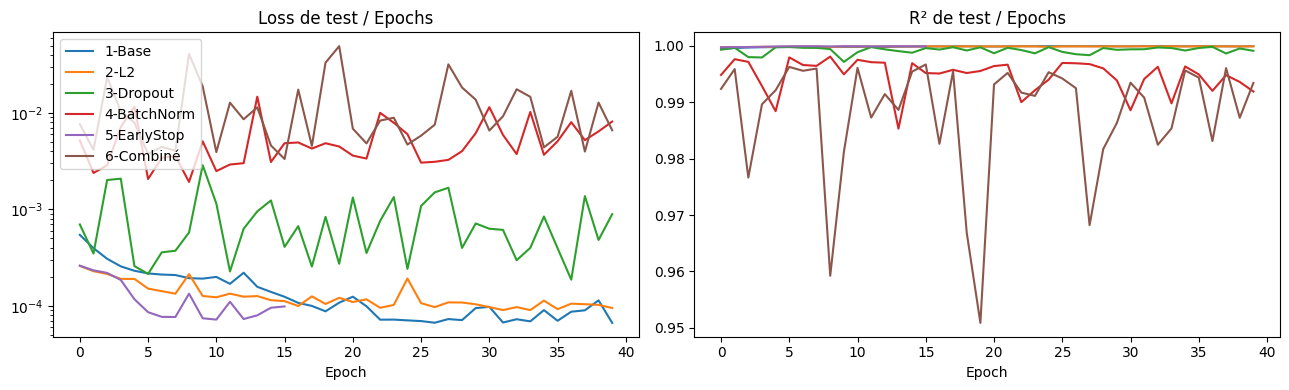

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, v in results.items():
    ax[0].plot(v["test_loss"], label=k)
    ax[1].plot(v["test_r2"], label=k)
ax[0].set_yscale("log"); ax[0].set_title("Loss de test / Epochs"); ax[0].set_xlabel("Epoch")
ax[1].set_title("R² de test / Epochs"); ax[1].set_xlabel("Epoch")
ax[0].legend()
plt.tight_layout()
plt.savefig(IMG + "comparaison.png", dpi=150, bbox_inches="tight")
plt.show()

J'ai comparé le modèle de base à cinq variantes régularisées (L2, Dropout, BatchNorm, Early Stopping et une combinaison) avec les mêmes hyperparamètres. Le modèle de base reste le meilleur (test loss 0,00007, R² = 0,99993), suivi de près par l'Early Stopping (0,99990, arrêté dès l'epoch 16) et la L2 (0,99991). Aucune technique n'améliore le résultat, car l'écart train/test était déjà nul : le modèle ne faisait pas d'overfitting, donc la régularisation n'avait rien à corriger.

Le Dropout (loss 0,00088) et surtout la BatchNorm (0,00816) et la combinaison (0,00663) dégradent la performance, avec des courbes très instables (le R² de la combinaison chute jusqu'à 0,95). Cela s'explique par le fait que le problème est quasi linéaire et la cible continue : ces techniques ajoutent du bruit ou perturbent les valeurs de sortie, ce qui bride un modèle qui n'en avait pas besoin. En conclusion, sur ce dataset la régularisation n'est pas utile, et l'Early Stopping est la plus intéressante car elle atteint presque la même précision en 2,5 fois moins d'epochs.


Synthèse personnelle 

Dans ce TP, j’ai découvert comment construire un réseau de neurones avec PyTorch, de la préparation des données jusqu’à l’évaluation. J’ai compris le rôle de chaque étape de la boucle d’entraînement (forward, calcul de la perte, backpropagation, mise à jour des poids) et comment les activations comme ReLU donnent au réseau sa capacité non linéaire.

J’ai aussi vu l’importance des hyperparamètres : le learning rate et l’optimiseur influencent beaucoup la vitesse de convergence, et le GridSearch permet de les choisir de façon systématique, même s’il coûte cher en temps de calcul. Pour cette raison, j’ai travaillé sur un sous-échantillon.

Sur la régularisation, j’ai compris qu’elle sert à lutter contre l’overfitting, mais qu’elle n’améliore pas forcément les résultats quand le modèle ne sur-apprend pas, comme ici.

Difficultés : le temps de calcul du GridSearch, le choix d’une métrique d’« accuracy » adaptée à la régression, et la gestion de la fuite de données lors de la normalisation.